<a href="https://colab.research.google.com/github/TanusnSN/4NI25CS208_DAV_LAB/blob/main/4NI25CS208_EXP_08.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score, f1_score)
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('/content/Titanic-Dataset.csv')

In [3]:
df=df.drop(['PassengerId','Name','Ticket','Cabin'],axis=1)
df['Age']=df['Age'].fillna(df['Age'].median())
df['Embarked']=df['Embarked'].fillna(df['Embarked'].mode()[0])
df['Sex']=df['Sex'].map({'male':0,'female':1})
df['Embarked']=df['Embarked'].map({'S':0,'C':1,'Q':2})

In [4]:
X=df[['Pclass','Sex','Age','SibSp','Parch','Fare','Embarked']]
y=df['Survived']

In [7]:
X_tr,X_te,y_tr,y_te = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [9]:
clf=LogisticRegression(max_iter=1000)
clf.fit(X_tr,y_tr)
y_pred=clf.predict(X_te)

In [11]:
print("Accuracy :",round(accuracy_score(y_te,y_pred),3))
print("Precision :",round(precision_score(y_te,y_pred),3))
print("Recall :",round(recall_score(y_te,y_pred),3))
print("F1-score :",round(f1_score(y_te,y_pred),3))
print("\n",classification_report(y_te,y_pred))

Accuracy : 0.804
Precision : 0.793
Recall : 0.667
F1-score : 0.724

               precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



Confusion Matrix:
 [[98 12]
 [23 46]]


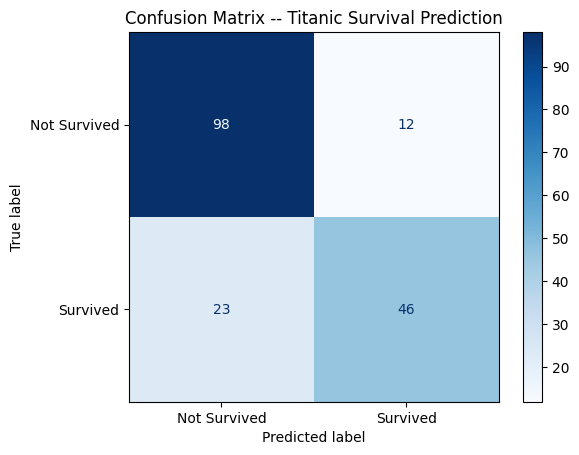

In [12]:
cm = confusion_matrix(y_te, y_pred, labels=[0, 1])
print('Confusion Matrix:\n', cm)
ConfusionMatrixDisplay(cm, display_labels=['Not Survived', 'Survived']).plot(cmap='Blues')
plt.title('Confusion Matrix -- Titanic Survival Prediction')
plt.show()